<a href="https://colab.research.google.com/github/nur-30/habit_tracker_app/blob/main/Medical_Insurance_Cost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("/insurance.csv")
print("Dataset berhasil dimuat")

Dataset berhasil dimuat


In [ ]:
# 2. head() output
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# 3. Dataset shape
print(df.shape)

(1338, 7)


In [ ]:
# 4. Column names
print(df.columns.tolist())

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [ ]:
# 5. Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
# 6. Statistical summary
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
print("Jumlah missing value per kolom:")
print(df.isnull().sum())
print("\nTotal missing value:", df.isnull().sum().sum())

Jumlah missing value per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing value: 0


In [ ]:
print("Jumlah data duplikat:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Jumlah data duplikat: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [ ]:
print("SEBELUM preprocessing")
print("Shape:", df.shape)
df.info()
df.head()

SEBELUM preprocessing
Shape: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# Hapus duplikat
df_clean = df.drop_duplicates().reset_index(drop=True)

# Rapikan teks kategorikal
for col in ["sex", "smoker", "region"]:
    df_clean[col] = df_clean[col].str.strip().str.lower()

# Encoding kategorikal -> numerik
df_encoded = pd.get_dummies(df_clean, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)

print("Setelah menghapus duplikat:", df_clean.shape)
print("Setelah encoding:", df_encoded.shape)
df_encoded.head()

Setelah menghapus duplikat: (1337, 7)
Setelah encoding: (1337, 9)


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [ ]:
print("SESUDAH preprocessing")
print("Shape:", df_encoded.shape)
df_encoded.info()
print("\nMissing value:", df_encoded.isnull().sum().sum())
print("Duplikat:", df_encoded.duplicated().sum())
df_encoded.head()

SESUDAH preprocessing
Shape: (1337, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1337 non-null   int64  
 1   bmi               1337 non-null   float64
 2   children          1337 non-null   int64  
 3   charges           1337 non-null   float64
 4   sex_male          1337 non-null   int64  
 5   smoker_yes        1337 non-null   int64  
 6   region_northwest  1337 non-null   int64  
 7   region_southeast  1337 non-null   int64  
 8   region_southwest  1337 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 94.1 KB

Missing value: 0
Duplikat: 0


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [ ]:
df_encoded.to_csv("insurance_cleaned.csv", index=False)

In [ ]:
df_encoded.head(10)

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0
5,31,25.740,0,3756.62160,0,0,0,1,0
6,46,33.440,1,8240.58960,0,0,0,1,0
7,37,27.740,3,7281.50560,0,0,1,0,0
8,37,29.830,2,6406.41070,1,0,0,0,0
9,60,25.840,0,28923.13692,0,0,1,0,0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

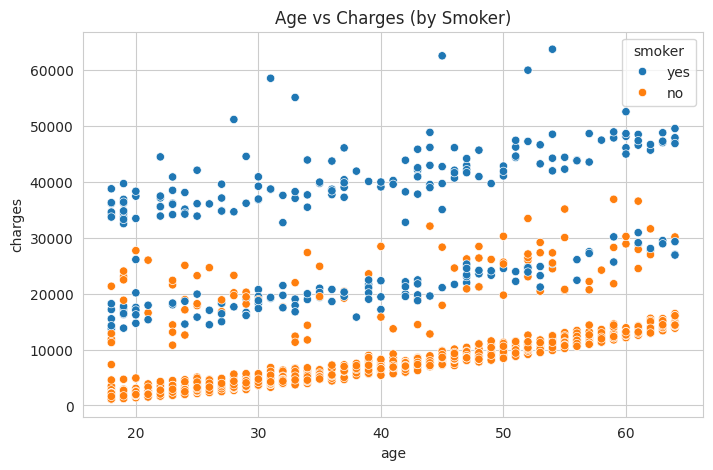

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="age", y="charges", hue="smoker")
plt.title("Age vs Charges (by Smoker)")
plt.show()

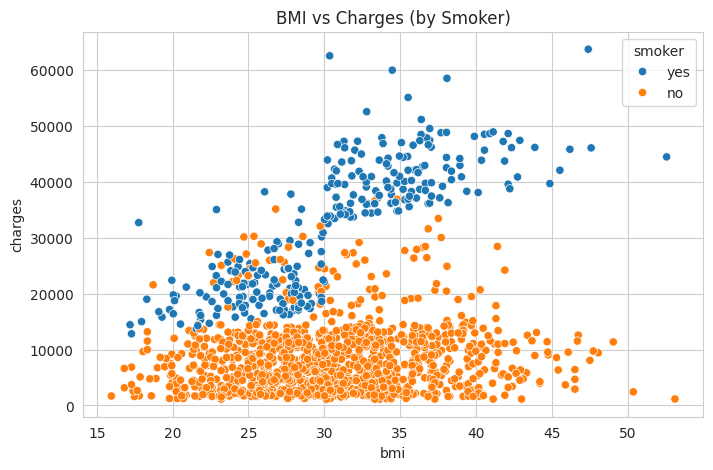

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs Charges (by Smoker)")
plt.show()

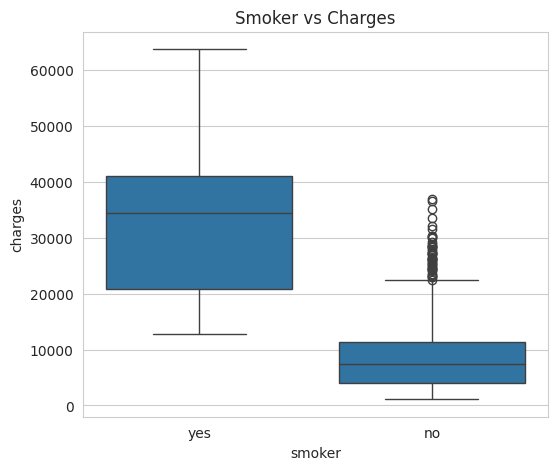

In [ ]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_clean, x="smoker", y="charges")
plt.title("Smoker vs Charges")
plt.show()

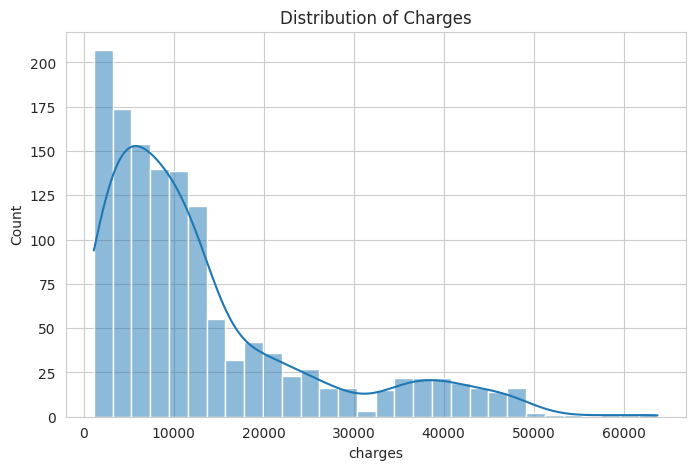

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["charges"], bins=30, kde=True)
plt.title("Distribution of Charges")
plt.show()

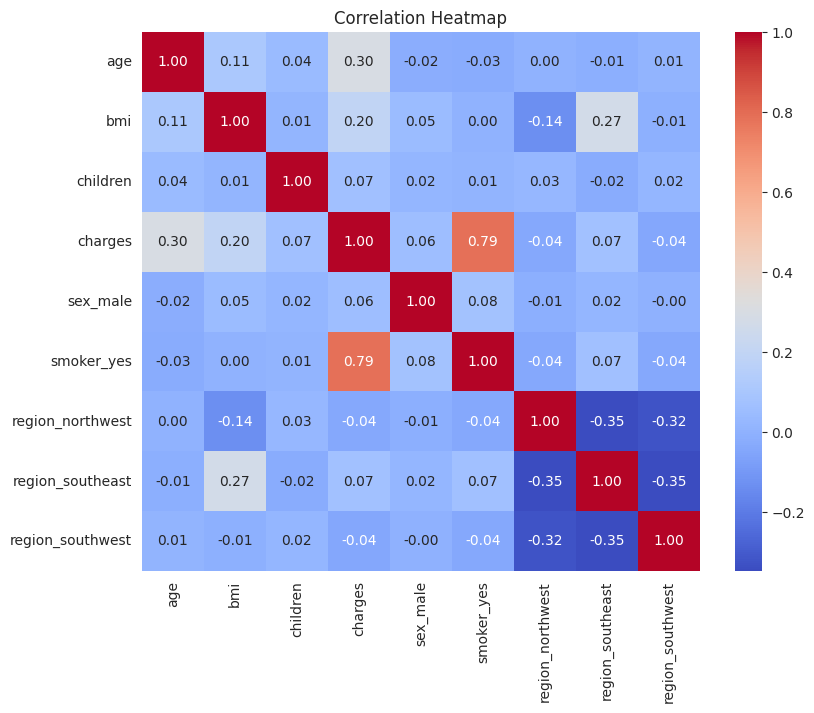

charges             1.000000
smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64


In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

print(df_encoded.corr()["charges"].sort_values(ascending=False))

1. Smoker adalah fitur paling berpengaruh. Korelasinya 0,79 dengan charges. Rata-rata biaya perokok sekitar $32.050, sedangkan non-perokok sekitar $8.441, atau kira-kira 4 kali lipat.

2. Usia berpengaruh positif. Semakin tua pelanggan, semakin tinggi biaya (korelasi 0,30). Scatter plot memperlihatkan tiga pita biaya yang naik seiring usia.

3. BMI berpengaruh terutama pada perokok. Korelasi BMI secara keseluruhan hanya 0,20. Namun perokok dengan BMI ≥ 30 rata-rata membayar sekitar $41.558, jauh di atas perokok BMI < 30 yang sekitar $21.363. Pada non-perokok, BMI hampir tidak membedakan biaya.

4. Sex, region, dan children berpengaruh kecil. Korelasinya semua di bawah 0,08, jadi bukan prediktor utama.

5. Distribusi charges miring ke kanan. Banyak biaya rendah dan sedikit biaya sangat tinggi (outlier), yang berhubungan dengan kelompok perokok.

In [ ]:
import pandas as pd

df = pd.read_csv("/insurance.csv") # jika error, pakai "/content/insurance.csv" atau "/insurance.csv"

df_clean = df.drop_duplicates().reset_index(drop=True)
for col in ["sex", "smoker", "region"]:
    df_clean[col] = df_clean[col].str.strip().str.lower()

df_encoded = pd.get_dummies(df_clean, columns=["sex", "smoker", "region"],
                            drop_first=True, dtype=int)

print("Shape df_encoded:", df_encoded.shape)   # harus (1337, 9)

Shape df_encoded: (1337, 9)


In [ ]:
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

print("Shape X:", X.shape)
print("Shape y:", y.shape)
X.head()

Shape X: (1337, 8)
Shape y: (1337,)


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1069, 8)
X_test : (268, 8)
y_train: (1069,)
y_test : (268,)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
print("Model berhasil dilatih!")
print("Intercept:", round(model.intercept_, 2))

coef = pd.DataFrame({"Fitur": X.columns, "Koefisien": model.coef_.round(2)})
print(coef)

print("\nR² data latih:", round(model.score(X_train, y_train), 4))
print("R² data uji  :", round(model.score(X_test, y_test), 4))

Model berhasil dilatih!
Intercept: -11092.65
              Fitur  Koefisien
0               age     248.21
1               bmi     318.70
2          children     533.01
3          sex_male    -101.54
4        smoker_yes   23077.76
5  region_northwest    -391.76
6  region_southeast    -838.92
7  region_southwest    -659.14

R² data latih: 0.7299
R² data uji  : 0.8069


In [ ]:
y_pred = model.predict(X_test)

hasil = pd.DataFrame({
    "Aktual": y_test.values[:10],
    "Prediksi": y_pred[:10].round(2)
})
hasil

,Aktual,Prediksi
0,8688.85885,8143.69
1,5708.86700,5737.12
2,11436.73815,14369.31
3,38746.35510,31745.51
4,4463.20510,8962.39
5,9304.70190,13149.72
6,38511.62830,30446.76
7,2150.46900,1453.29
8,7345.72660,10633.02
9,10264.44210,11318.94


In [ ]:
import pandas as pd, os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

path = next(p for p in ["insurance.csv", "/content/insurance.csv", "/insurance.csv"] if os.path.exists(p))
df = pd.read_csv(path)

# Phase 3: cleaning + encoding
df_clean = df.drop_duplicates().reset_index(drop=True)
for col in ["sex", "smoker", "region"]:
    df_clean[col] = df_clean[col].str.strip().str.lower()
df_encoded = pd.get_dummies(df_clean, columns=["sex", "smoker", "region"],
                            drop_first=True, dtype=int)

# Phase 5: split + training
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)

print("File dimuat dari:", path)
print("df_encoded:", df_encoded.shape, "| X_test:", X_test.shape)

File dimuat dari: insurance.csv
df_encoded: (1337, 9) | X_test: (268, 8)


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
print("MAE  :", round(mae, 2))

MAE  : 4177.05


In [ ]:
mse = mean_squared_error(y_test, y_pred)
print("MSE  :", round(mse, 2))

MSE  : 35478020.68


In [ ]:
rmse = np.sqrt(mse)
print("RMSE :", round(rmse, 2))

RMSE : 5956.34


In [ ]:
r2 = r2_score(y_test, y_pred)
print("R² Score:", round(r2, 4))

R² Score: 0.8069


In [ ]:
hasil = pd.DataFrame({
    "Aktual": y_test.values[:10],
    "Prediksi": y_pred[:10].round(2)
})
hasil["Selisih"] = (hasil["Aktual"] - hasil["Prediksi"]).round(2)
hasil

,Aktual,Prediksi,Selisih
0,8688.85885,8143.69,545.17
1,5708.86700,5737.12,-28.25
2,11436.73815,14369.31,-2932.57
3,38746.35510,31745.51,7000.85
4,4463.20510,8962.39,-4499.18
5,9304.70190,13149.72,-3845.02
6,38511.62830,30446.76,8064.87
7,2150.46900,1453.29,697.18
8,7345.72660,10633.02,-3287.29
9,10264.44210,11318.94,-1054.50


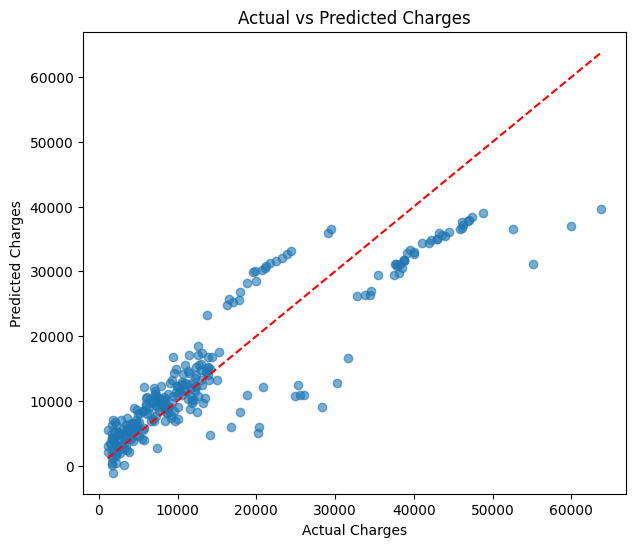

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")
plt.show()

In [ ]:
def predict_cost(age, bmi, children, sex, smoker, region):
    # Susun input dengan format & urutan kolom yang sama seperti saat training
    row = {col: 0 for col in X.columns}
    row["age"] = age
    row["bmi"] = bmi
    row["children"] = children
    row["sex_male"] = 1 if sex == "male" else 0
    row["smoker_yes"] = 1 if smoker == "yes" else 0
    if region != "northeast":          # northeast = kategori acuan (drop_first)
        row["region_" + region] = 1
    data = pd.DataFrame([row], columns=X.columns)
    return model.predict(data)[0]

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

w_age = widgets.IntSlider(value=30, min=18, max=64, description="Age:")
w_bmi = widgets.FloatSlider(value=25.0, min=15, max=55, step=0.1, description="BMI:")
w_children = widgets.IntSlider(value=0, min=0, max=5, description="Children:")
w_sex = widgets.Dropdown(options=["female", "male"], description="Gender:")
w_smoker = widgets.Dropdown(options=["no", "yes"], description="Smoker:")
w_region = widgets.Dropdown(options=["northeast", "northwest", "southeast", "southwest"], description="Region:")
btn = widgets.Button(description="Predict Cost", button_style="success")
out = widgets.Output()

def on_click(b):
    with out:
        clear_output()
        hasil = predict_cost(w_age.value, w_bmi.value, w_children.value,
                             w_sex.value, w_smoker.value, w_region.value)
        print(f"Estimated Insurance Cost: ${hasil:,.2f}")

btn.on_click(on_click)

print("🏥 MEDICAL INSURANCE COST PREDICTION")
display(w_age, w_bmi, w_children, w_sex, w_smoker, w_region, btn, out)

🏥 MEDICAL INSURANCE COST PREDICTION


IntSlider(value=30, description='Age:', max=64, min=18)

FloatSlider(value=25.0, description='BMI:', max=55.0, min=15.0)

IntSlider(value=0, description='Children:', max=5)

Dropdown(description='Gender:', options=('female', 'male'), value='female')

Dropdown(description='Smoker:', options=('no', 'yes'), value='no')

Dropdown(description='Region:', options=('northeast', 'northwest', 'southeast', 'southwest'), value='northeast…

Button(button_style='success', description='Predict Cost', style=ButtonStyle())

Output()